
Training: (256, 128, 64), Activation: relu
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.3201 - loss: 1.8748
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.3952 - loss: 1.6811
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.4247 - loss: 1.6046
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.4441 - loss: 1.5476
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.4579 - loss: 1.5092

Training: (256, 128, 64), Activation: tanh
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.2574 - loss: 2.0100
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.3161 - loss: 1.8752
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.3359 - loss: 1.8327
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.3486 - loss: 1.8015
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.3526 - loss: 1.7887

Training: (256, 128, 64), Activation: sig

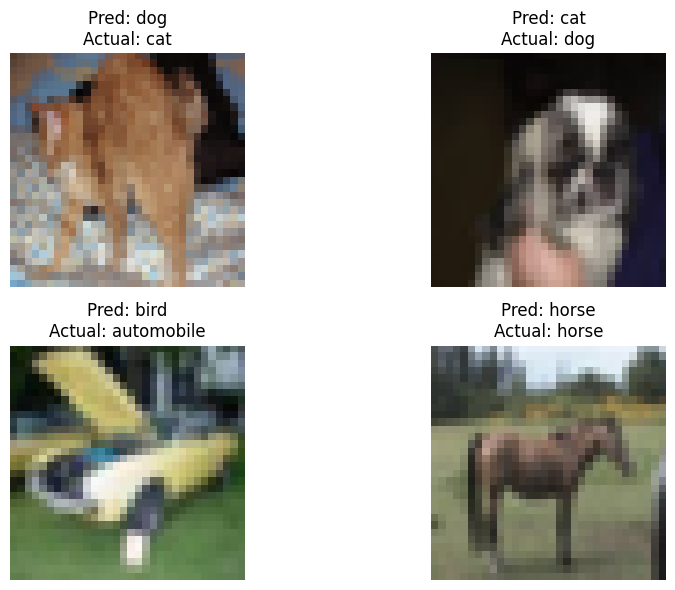

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Class names
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

# Hidden layer configurations
hidden_units = [
    (256, 128, 64),
    (512, 256, 128),
    (1024, 512, 256)
]

activations = ['relu', 'tanh', 'sigmoid']

results = []
best_acc = 0

# Train 9 models
for units in hidden_units:
    for act in activations:

        model = Sequential([
            Input(shape=(32, 32, 3)),
            Flatten(),
            Dense(units[0], activation=act),
            Dense(units[1], activation=act),
            Dense(units[2], activation=act),
            Dense(10, activation='softmax')
        ])

        model.compile(
            optimizer='adam',
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        print(f"\nTraining: {units}, Activation: {act}")

        model.fit(
            x_train, y_train,
            epochs=5,
            batch_size=64,
            verbose=1
        )

        loss, acc = model.evaluate(x_test, y_test, verbose=0)

        results.append([
            *units, act, round(loss, 4), round(acc * 100, 2)
        ])

        if acc > best_acc:
            best_acc = acc
            best_model = model
            best_units = units
            best_act = act

# Display comparison table
df = pd.DataFrame(results, columns=[
    'HL1', 'HL2', 'HL3', 'Activation',
    'Test Loss', 'Test Accuracy'
])

print("\nMODEL COMPARISON")
print(df.to_string(index=False))

# Display best model
print("\nBEST MODEL")
print("Hidden units:", best_units)
print("Activation:", best_act)
print("Accuracy:", round(best_acc * 100, 2), "%")

# Predict last 4 images
pred = best_model.predict(x_test[-4:], verbose=0)

plt.figure(figsize=(10, 6))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    predicted = np.argmax(pred[i])
    actual = np.argmax(y_test[-4 + i])

    plt.imshow(x_test[-4 + i])
    plt.title(f'Pred: {classes[predicted]}\nActual: {classes[actual]}')
    plt.axis('off')

plt.tight_layout()
plt.show()